# Sparse VAEの理論説明図

教授への研究報告用：**主図9点＋補足2点**。スライド本体は作成しません。

- 上から順に「すべて実行」すると、各図を表示し、`reports/sparse_vae_theory/figures/`へPNG（3200×1800）・SVGを保存します。
- 図は**模式図・仮想値・説明用の線形モデル**です。学習済みSparse VAEの実測結果ではありません。
- 「疎」は一部の成分への依存が弱くなることを説明します。αは相対ノイズであり、重要度そのものではありません。
- 再学習・モデル評価・OneDriveへの保存は行いません。
- 乱数シード：42。依存：NumPy、Matplotlib、SciPy、Pillow、scikit-image。

出典・詳しい注意事項は [README](../../reports/sparse_vae_theory/README.md) を参照してください。

In [1]:
from pathlib import Path
import json, platform, hashlib
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib import font_manager
from scipy.special import expit
from scipy.stats import norm
from skimage.metrics import structural_similarity
from PIL import Image
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/'memory/memory.md').is_file() and (p/'code').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('リポジトリ内で実行してください。')
OUT = ROOT/'reports/sparse_vae_theory/figures'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
FONT = next((name for name in ['Meiryo','Yu Gothic','Noto Sans CJK JP','IPAexGothic']
             if name in {f.name for f in font_manager.fontManager.ttflist}), 'DejaVu Sans')
plt.rcParams.update({'font.family':FONT, 'font.size':16, 'axes.labelsize':17,
                    'axes.titlesize':19, 'xtick.labelsize':14,'ytick.labelsize':14,
                    'legend.fontsize':14, 'axes.spines.top':False,
                    'axes.spines.right':False,'axes.unicode_minus':False,
                    'svg.fonttype':'path','figure.facecolor':'white','savefig.facecolor':'white'})
C = dict(ink='#2e2b21', muted='#605b4f', olive='#777744', teal='#287c80',
         red='#b45342', pale='#eef4f3', sand='#f1f0e6', blue='#446c9b', line='#c6ccc8')
FIGURES=[]
TEXT_WARNINGS=[]

def canvas(title, subtitle):
    fig=plt.figure(figsize=(16,9),facecolor='white')
    fig.text(.045,.955,title,fontsize=25,weight='bold',color=C['ink'],va='top')
    fig.text(.045,.895,subtitle,fontsize=16,color=C['muted'],va='top')
    return fig

def foot(fig, text):
    fig.text(.045,.035,text,fontsize=13,color=C['muted'],va='bottom',linespacing=1.6)

def note(ax, xy, text, width=.24, height=.14, color=None, fontsize=18):
    x,y=xy
    box=FancyBboxPatch((x,y),width,height,boxstyle='round,pad=0.012,rounding_size=0.018',
                      facecolor=color or C['pale'],edgecolor=C['line'],transform=ax.transAxes,clip_on=False)
    ax.add_patch(box)
    ax.text(x+width/2,y+height/2,text,ha='center',va='center',fontsize=fontsize,
            color=C['ink'],transform=ax.transAxes,linespacing=1.7)

def arrow(ax,a,b,color=None):
    ax.add_patch(FancyArrowPatch(a,b,arrowstyle='-|>',mutation_scale=22,lw=2,
                               color=color or C['teal'],transform=ax.transAxes))

def grid(ax):
    ax.grid(alpha=.22,ls='--'); ax.set_axisbelow(True)

def finish(fig,stem):
    # 固定された16:9のキャンバスを保存。bbox_inches='tight'は使わない。
    fig.canvas.draw()
    renderer=fig.canvas.get_renderer(); bounds=fig.bbox
    for t in fig.findobj(matplotlib.text.Text):
        if not t.get_visible() or not t.get_text(): continue
        b=t.get_window_extent(renderer)
        if b.width>0 and (b.x0 < -1 or b.y0 < -1 or b.x1>bounds.x1+1 or b.y1>bounds.y1+1):
            TEXT_WARNINGS.append((stem,t.get_text()))
    png=OUT/(stem+'.png'); svg=OUT/(stem+'.svg')
    fig.savefig(png,dpi=200,metadata={'Software':'Sparse VAE theory figures; seed=42'})
    fig.savefig(svg,metadata={'Date':None,'Creator':'Sparse VAE theory figures'})
    svg.write_text('\n'.join(line.rstrip() for line in svg.read_text(encoding='utf-8').splitlines())+'\n',encoding='utf-8')
    FIGURES.append(stem)
    display(fig)
    plt.close(fig)

# 理想化された数式。公式実装の数値安定化はREADMEに分けて記載。
def sparse_R(ell, clamp=False):
    ell=np.asarray(ell,dtype=float)
    if clamp: ell=np.clip(ell,-8,8)
    return -.63576*expit(1.87320+1.48695*ell)+.5*np.logaddexp(0,-ell)+.63576

def bottle(chipped=False,n=128):
    yy,xx=np.mgrid[-1:1:complex(n),-1:1:complex(n)]
    r=np.sqrt(xx**2+yy**2)
    im=np.full((n,n),.96)
    im[r<.79]=.28; im[r<.63]=.12
    im[(r>.68)&(r<.72)]=.48
    if chipped: im[(xx>.38)&(yy<-.35)&(xx+yy<.12)&(r>.58)&(r<.84)]=.96
    return im
NORMAL=bottle(); ABNORMAL=bottle(True)

## 図1：異常まで復元すると、差が消える

正常だけで学習しても、モデルが未知の異常を保持する場合があります。「期待する復元」は目標の模式図で、必ず起こる動作ではありません。この図の差分は**画素値の絶対差**です（SSIMは図9）。

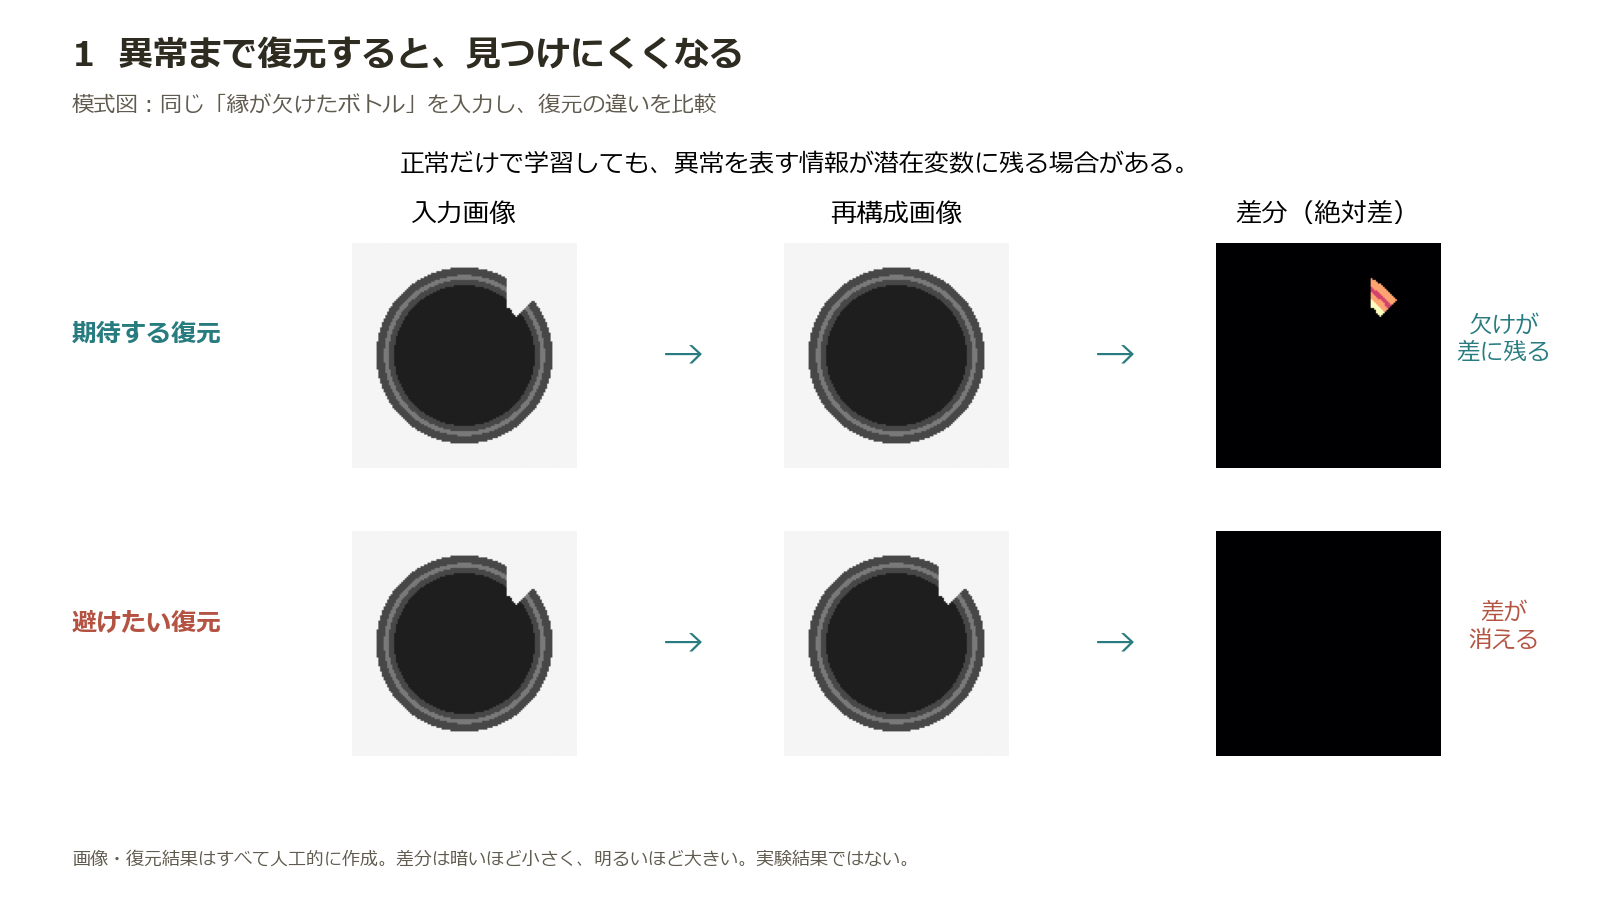

In [2]:
fig=canvas('1  異常まで復元すると、見つけにくくなる','模式図：同じ「縁が欠けたボトル」を入力し、復元の違いを比較')
fig.text(.5,.81,'正常だけで学習しても、異常を表す情報が潜在変数に残る場合がある。',ha='center',fontsize=18)
xs=[.19,.46,.73]; ys=[.48,.16]
for row,(recon,label) in enumerate([(NORMAL,'期待する復元'),(ABNORMAL,'避けたい復元')]):
    fig.text(.045,ys[row]+.14,label,fontsize=18,weight='bold',color=C['teal'] if row==0 else C['red'])
    for col,(im,heading) in enumerate(zip([ABNORMAL,recon,np.abs(ABNORMAL-recon)],['入力画像','再構成画像','差分（絶対差）'])):
        ax=fig.add_axes([xs[col],ys[row],.20,.25])
        if col<2: ax.imshow(im,cmap='gray',vmin=0,vmax=1)
        else: ax.imshow(im,cmap='magma',vmin=0,vmax=.84)
        ax.axis('off')
        if row==0: ax.set_title(heading,pad=15)
    fig.text(.415,ys[row]+.11,'→',fontsize=28,color=C['teal'])
    fig.text(.685,ys[row]+.11,'→',fontsize=28,color=C['teal'])
fig.text(.94,.60,'欠けが\n差に残る',ha='center',fontsize=17,color=C['teal'])
fig.text(.94,.28,'差が\n消える',ha='center',fontsize=17,color=C['red'])
foot(fig,'画像・復元結果はすべて人工的に作成。差分は暗いほど小さく、明るいほど大きい。実験結果ではない。')
finish(fig,'01_異常まで再構成する問題')

## 図2：「疎」は、一部の成分への依存を弱めるという説明

棒は概念説明のために設定した仮想値です。αやμの値、学習済みデコーダの感度を測った結果ではありません。通常VAEでも利用が偏る場合があり、各次元に決まった意味が割り当てられるとは限りません。

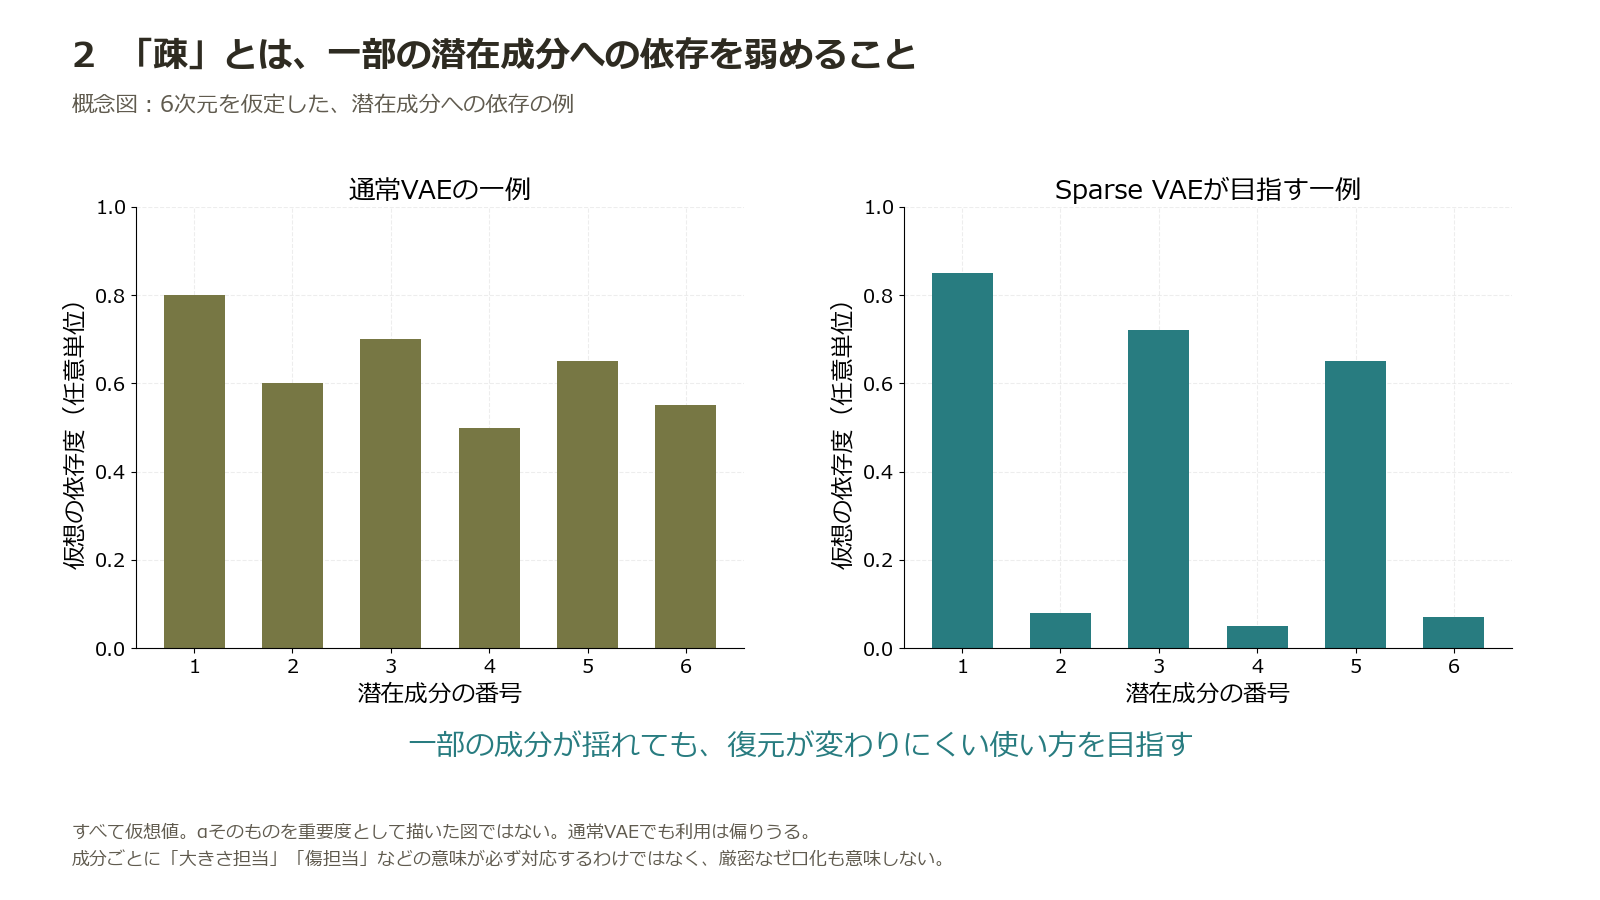

In [3]:
fig=canvas('2  「疎」とは、一部の潜在成分への依存を弱めること','概念図：6次元を仮定した、潜在成分への依存の例')
for k,(title,values,color) in enumerate([
    ('通常VAEの一例',[.8,.6,.7,.5,.65,.55],C['olive']),
    ('Sparse VAEが目指す一例',[.85,.08,.72,.05,.65,.07],C['teal'])]):
    ax=fig.add_axes([.085+k*.48,.28,.38,.49]);ax.bar(np.arange(1,7),values,color=color,width=.62)
    ax.set(title=title,xlabel='潜在成分の番号',ylabel='仮想の依存度（任意単位）',ylim=(0,1),xticks=np.arange(1,7));grid(ax)
fig.text(.5,.16,'一部の成分が揺れても、復元が変わりにくい使い方を目指す',ha='center',fontsize=21,color=C['teal'])
foot(fig,'すべて仮想値。αそのものを重要度として描いた図ではない。通常VAEでも利用は偏りうる。\n成分ごとに「大きさ担当」「傷担当」などの意味が必ず対応するわけではなく、厳密なゼロ化も意味しない。')
finish(fig,'02_潜在成分への依存の概念')

## 図3：同じμでも、学習時には異なるzを使う

Gaussian Dropoutは平均1の正規乱数を掛ける操作です。一定割合を厳密に0にするBernoulli Dropoutとは異なります。比較には同じε列を使います。ノイズなしは比較用のα=0で、log αを学ぶ実装の有限パラメータ値ではありません。

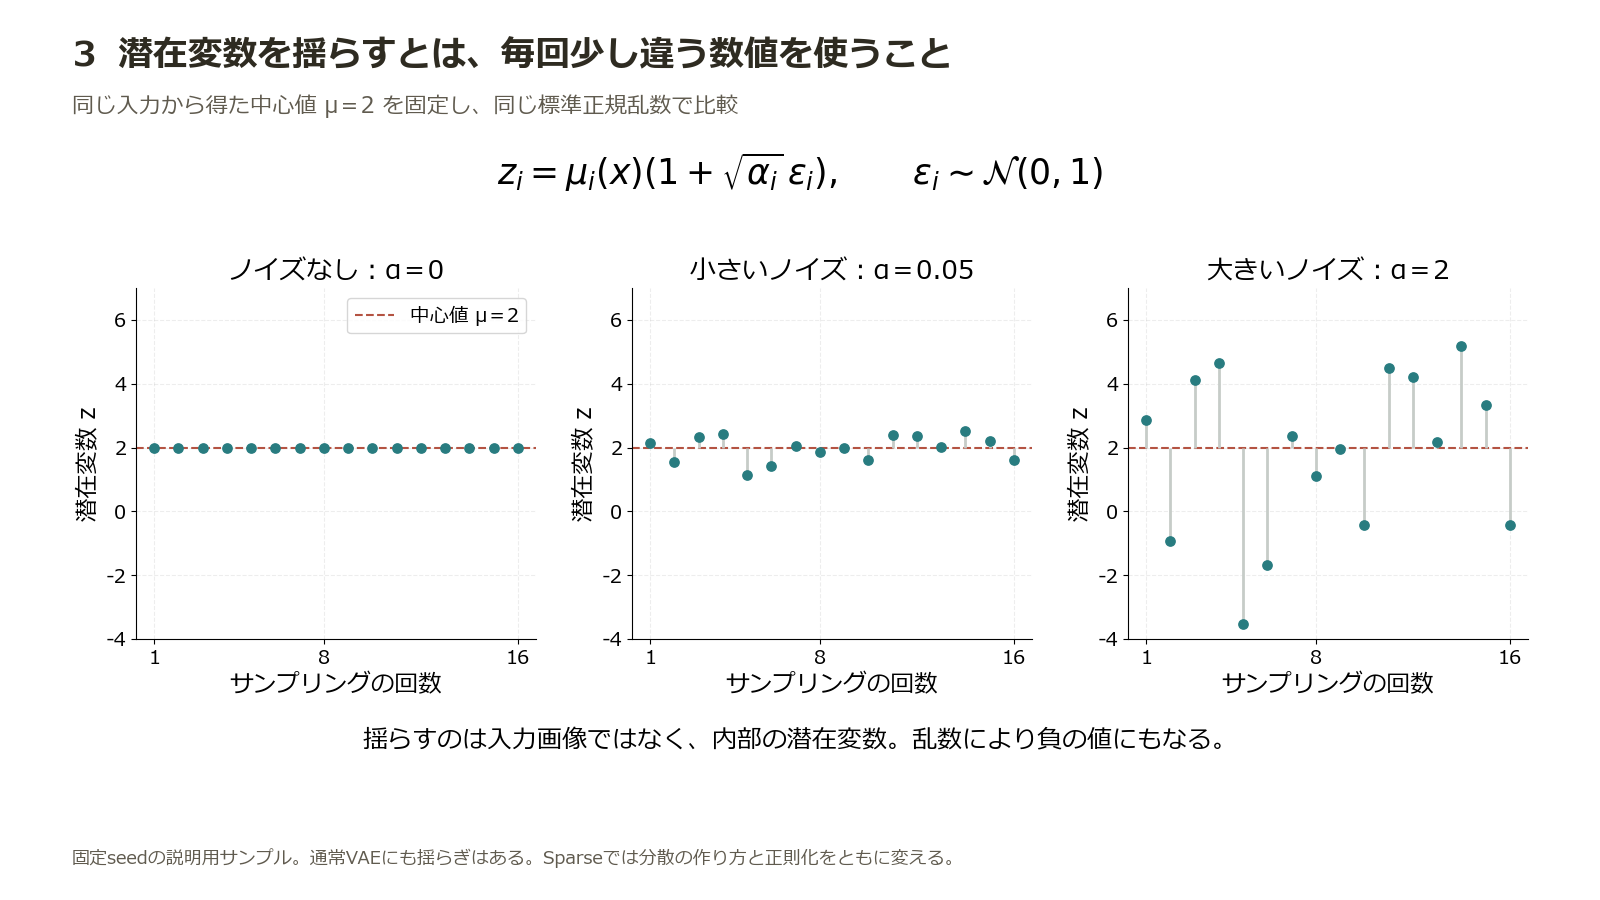

In [4]:
fig=canvas('3  潜在変数を揺らすとは、毎回少し違う数値を使うこと','同じ入力から得た中心値 μ＝2 を固定し、同じ標準正規乱数で比較')
fig.text(.5,.795,r'$z_i=\mu_i(x)(1+\sqrt{\alpha_i}\,\epsilon_i),\qquad \epsilon_i\sim\mathcal{N}(0,1)$',ha='center',fontsize=25)
eps=np.random.default_rng(SEED).normal(size=16)
for k,(a,title) in enumerate([(0,'ノイズなし'),(.05,'小さいノイズ'),(2,'大きいノイズ')]):
    ax=fig.add_axes([.085+k*.31,.29,.25,.39]); z=2*(1+np.sqrt(a)*eps)
    ax.axhline(2,color=C['red'],ls='--',label='中心値 μ＝2')
    ax.vlines(np.arange(1,17),2,z,color=C['line'],lw=2);ax.scatter(np.arange(1,17),z,color=C['teal'],s=45,zorder=3)
    ax.set(title=f'{title}：α＝{a:g}',xlabel='サンプリングの回数',ylabel='潜在変数 z',ylim=(-4,7),xticks=[1,8,16]);grid(ax)
    if k==0:ax.legend(loc='upper right')
fig.text(.5,.17,'揺らすのは入力画像ではなく、内部の潜在変数。乱数により負の値にもなる。',ha='center',fontsize=18)
foot(fig,'固定seedの説明用サンプル。通常VAEにも揺らぎはある。Sparseでは分散の作り方と正則化をともに変える。')
finish(fig,'03_潜在変数のサンプリング')

## 図4：αは相対ノイズの強さ

平均μ、分散αμ²、標準偏差|μ|√αです。分散は幅そのものではなく、標準偏差の二乗です。

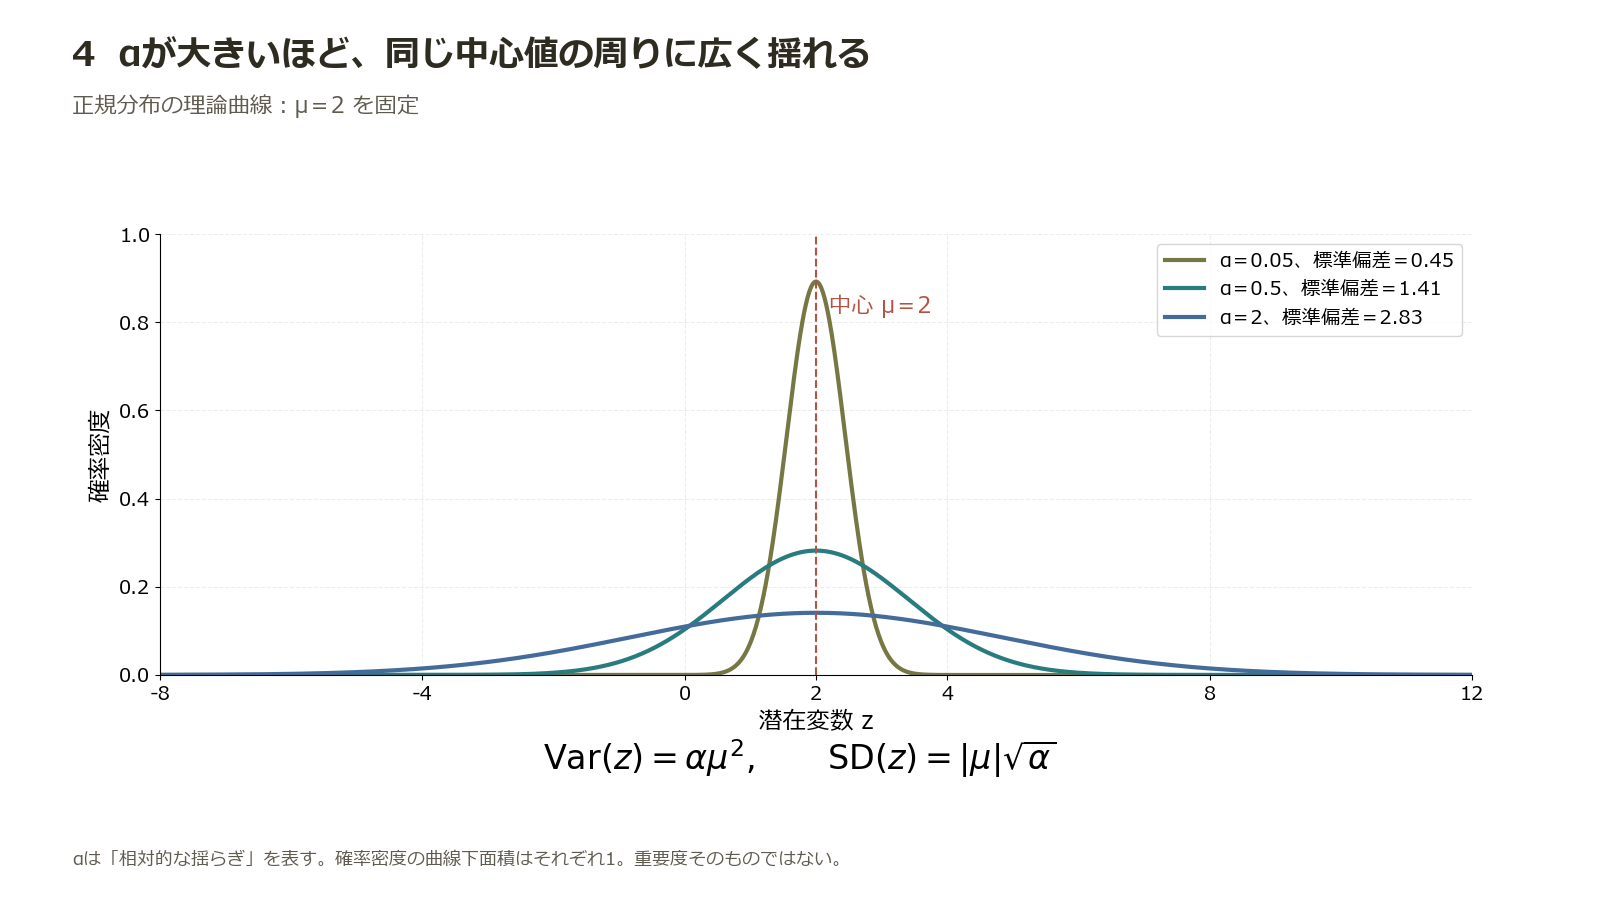

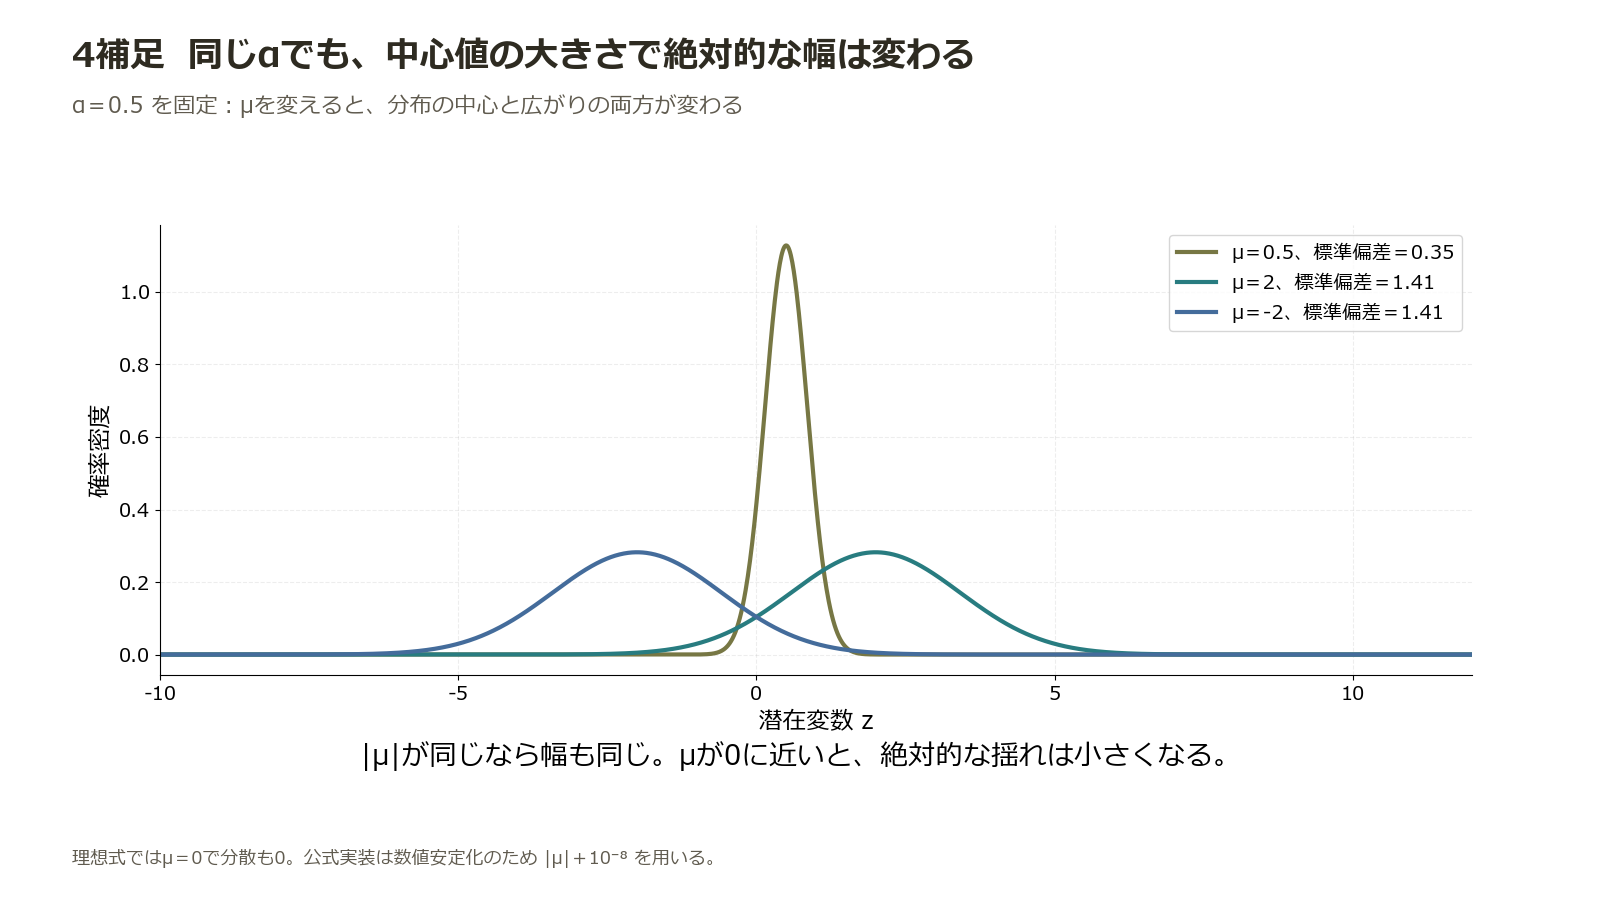

In [5]:
fig=canvas('4  αが大きいほど、同じ中心値の周りに広く揺れる','正規分布の理論曲線：μ＝2 を固定')
ax=fig.add_axes([.10,.25,.82,.49]);xx=np.linspace(-8,12,1600)
for a,color in zip([.05,.5,2],[C['olive'],C['teal'],C['blue']]):
    sd=2*np.sqrt(a);ax.plot(xx,norm.pdf(xx,2,sd),lw=3,color=color,label=f'α＝{a:g}、標準偏差＝{sd:.2f}')
ax.axvline(2,color=C['red'],ls='--',lw=1.5);ax.text(2.2,.82,'中心 μ＝2',fontsize=16,color=C['red'])
ax.set(xlabel='潜在変数 z',ylabel='確率密度',ylim=(0,1),xlim=(-8,12),xticks=[-8,-4,0,2,4,8,12]);ax.legend(loc='upper right');grid(ax)
fig.text(.5,.145,r'$\mathrm{Var}(z)=\alpha\mu^2,\qquad \mathrm{SD}(z)=|\mu|\sqrt{\alpha}$',fontsize=24,ha='center')
foot(fig,'αは「相対的な揺らぎ」を表す。確率密度の曲線下面積はそれぞれ1。重要度そのものではない。')
finish(fig,'04_αと分布の広がり')

fig=canvas('4補足  同じαでも、中心値の大きさで絶対的な幅は変わる','α＝0.5 を固定：μを変えると、分布の中心と広がりの両方が変わる')
ax=fig.add_axes([.10,.25,.82,.50]);xx=np.linspace(-10,12,1800)
for mu,color in zip([.5,2,-2],[C['olive'],C['teal'],C['blue']]):
    sd=abs(mu)*np.sqrt(.5);ax.plot(xx,norm.pdf(xx,mu,sd),lw=3,color=color,label=f'μ＝{mu:g}、標準偏差＝{sd:.2f}')
ax.set(xlabel='潜在変数 z',ylabel='確率密度',xlim=(-10,12),xticks=[-10,-5,0,5,10]);ax.legend(loc='upper right');grid(ax)
fig.text(.5,.15,'|μ|が同じなら幅も同じ。μが0に近いと、絶対的な揺れは小さくなる。',ha='center',fontsize=20)
foot(fig,'理想式ではμ＝0で分散も0。公式実装は数値安定化のため |μ|＋10⁻⁸ を用いる。')
finish(fig,'04b_μによる絶対ノイズの違い')

## 図5：小さな潜在変化に出力が敏感だと、ノイズの影響が大きい

横軸は一つの潜在成分、縦軸は出力の一つの特徴を表す説明用の関数です。実際の画像やCNNデコーダの感度を測定した図ではありません。

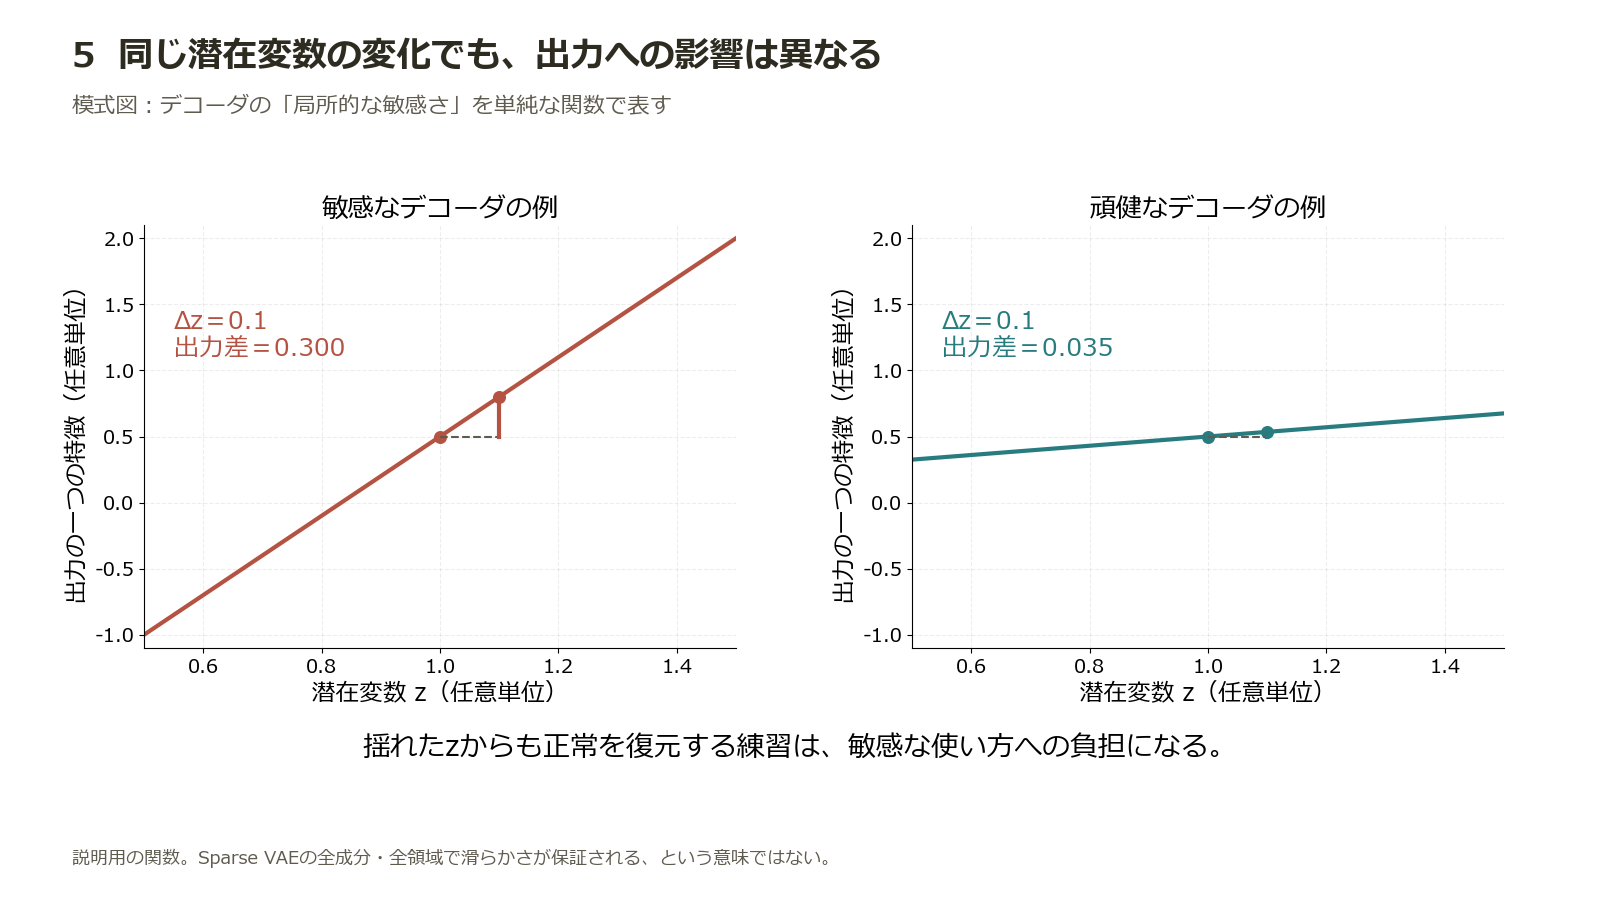

In [6]:
fig=canvas('5  同じ潜在変数の変化でも、出力への影響は異なる','模式図：デコーダの「局所的な敏感さ」を単純な関数で表す')
for k,(slope,title,col) in enumerate([(3,'敏感なデコーダの例',C['red']),(.35,'頑健なデコーダの例',C['teal'])]):
    ax=fig.add_axes([.09+k*.48,.28,.37,.47]);z=np.linspace(.5,1.5,100); y=.5+slope*(z-1)
    ax.plot(z,y,color=col,lw=3);ax.scatter([1,1.1],[.5,.5+slope*.1],s=70,color=col)
    ax.plot([1,1.1],[.5,.5],color=C['muted'],ls='--');ax.plot([1.1,1.1],[.5,.5+slope*.1],color=col,lw=3)
    ax.text(.55,1.1,f'Δz＝0.1\n出力差＝{slope*.1:.3f}',fontsize=18,color=col)
    ax.set(title=title,xlabel='潜在変数 z（任意単位）',ylabel='出力の一つの特徴（任意単位）',xlim=(.5,1.5),ylim=(-1.1,2.1));grid(ax)
fig.text(.5,.16,'揺れたzからも正常を復元する練習は、敏感な使い方への負担になる。',ha='center',fontsize=20)
foot(fig,'説明用の関数。Sparse VAEの全成分・全領域で滑らかさが保証される、という意味ではない。')
finish(fig,'05_敏感なデコーダと頑健なデコーダ')

## 図6：必要な情報まで揺らすと、復元誤差が増える

ほかの条件を固定した仮想例です。実際にはμ・デコーダ・αが同時に変化し、情報が別の次元へ移る場合もあります。この曲線からαだけで重要度を決めることはできません。

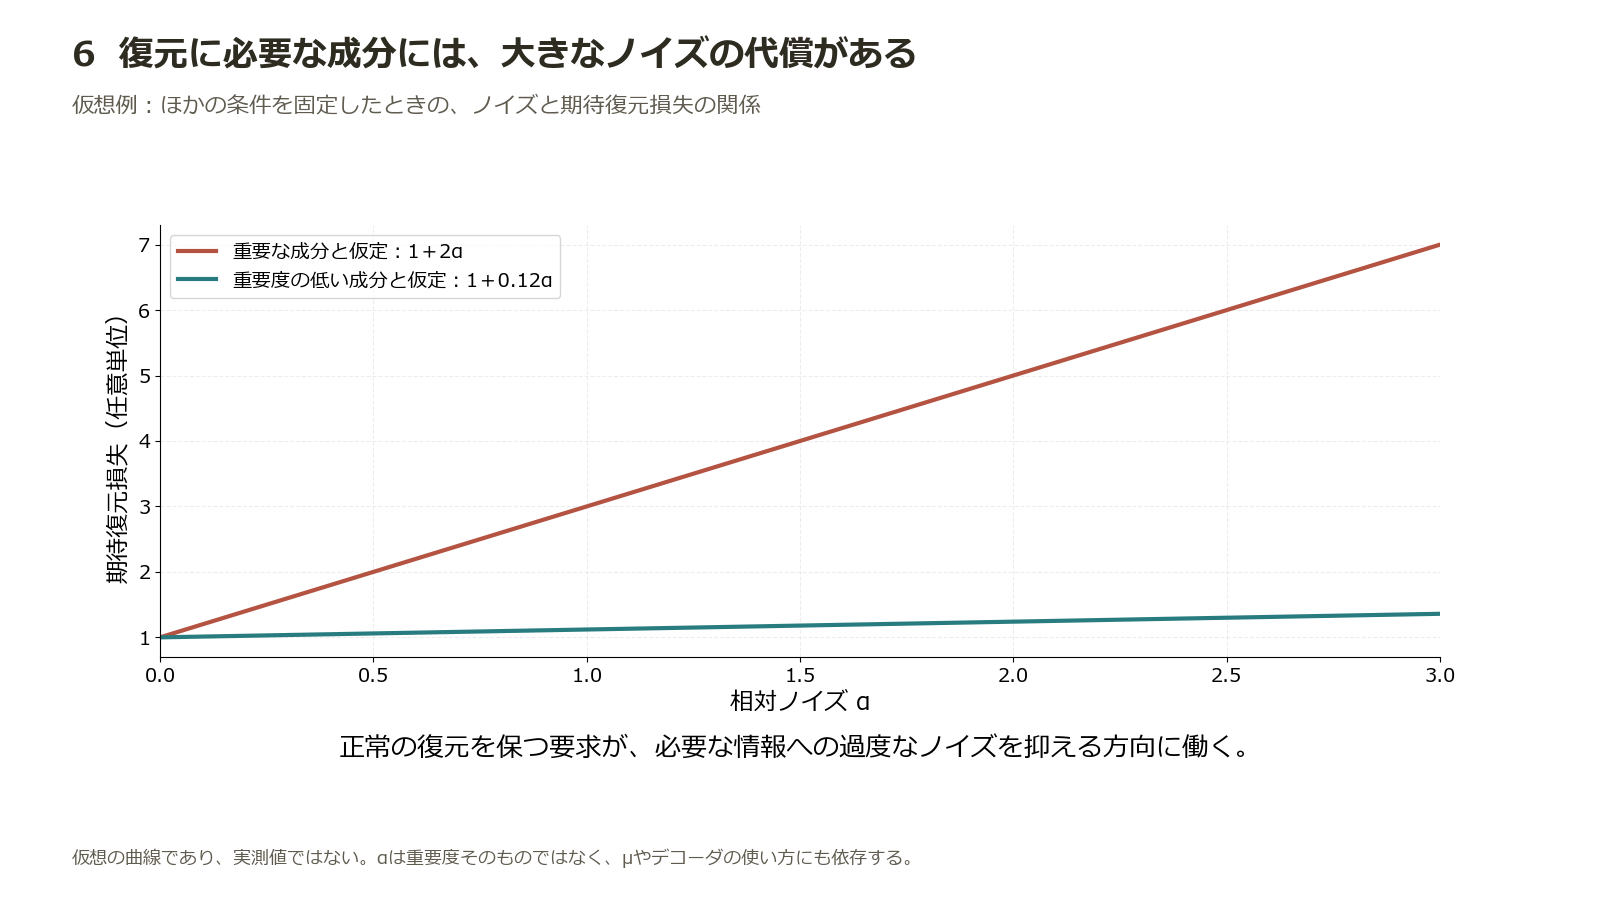

In [7]:
fig=canvas('6  復元に必要な成分には、大きなノイズの代償がある','仮想例：ほかの条件を固定したときの、ノイズと期待復元損失の関係')
ax=fig.add_axes([.10,.27,.80,.48]);a=np.linspace(0,3,150)
ax.plot(a,1+2*a,lw=3,color=C['red'],label='重要な成分と仮定：1＋2α')
ax.plot(a,1+.12*a,lw=3,color=C['teal'],label='重要度の低い成分と仮定：1＋0.12α')
ax.set(xlabel='相対ノイズ α',ylabel='期待復元損失（任意単位）',xlim=(0,3));ax.legend(loc='upper left');grid(ax)
fig.text(.5,.16,'正常の復元を保つ要求が、必要な情報への過度なノイズを抑える方向に働く。',ha='center',fontsize=19)
foot(fig,'仮想の曲線であり、実測値ではない。αは重要度そのものではなく、μやデコーダの使い方にも依存する。')
finish(fig,'06_成分による復元損失の違い')

## 図7：復元と正則化のバランス

$L=L_{\rm recon}+\beta\sum_i R(\log\alpha_i)$。

本文図は**一成分の説明用モデル**です。復元項は1+0.6α、β=1と仮定します。実際の学習中はほかのパラメータも変わります。補足図のRは、著者指定MultiVae実装の近似式そのものです。標準正規事前への通常KLとは異なります。

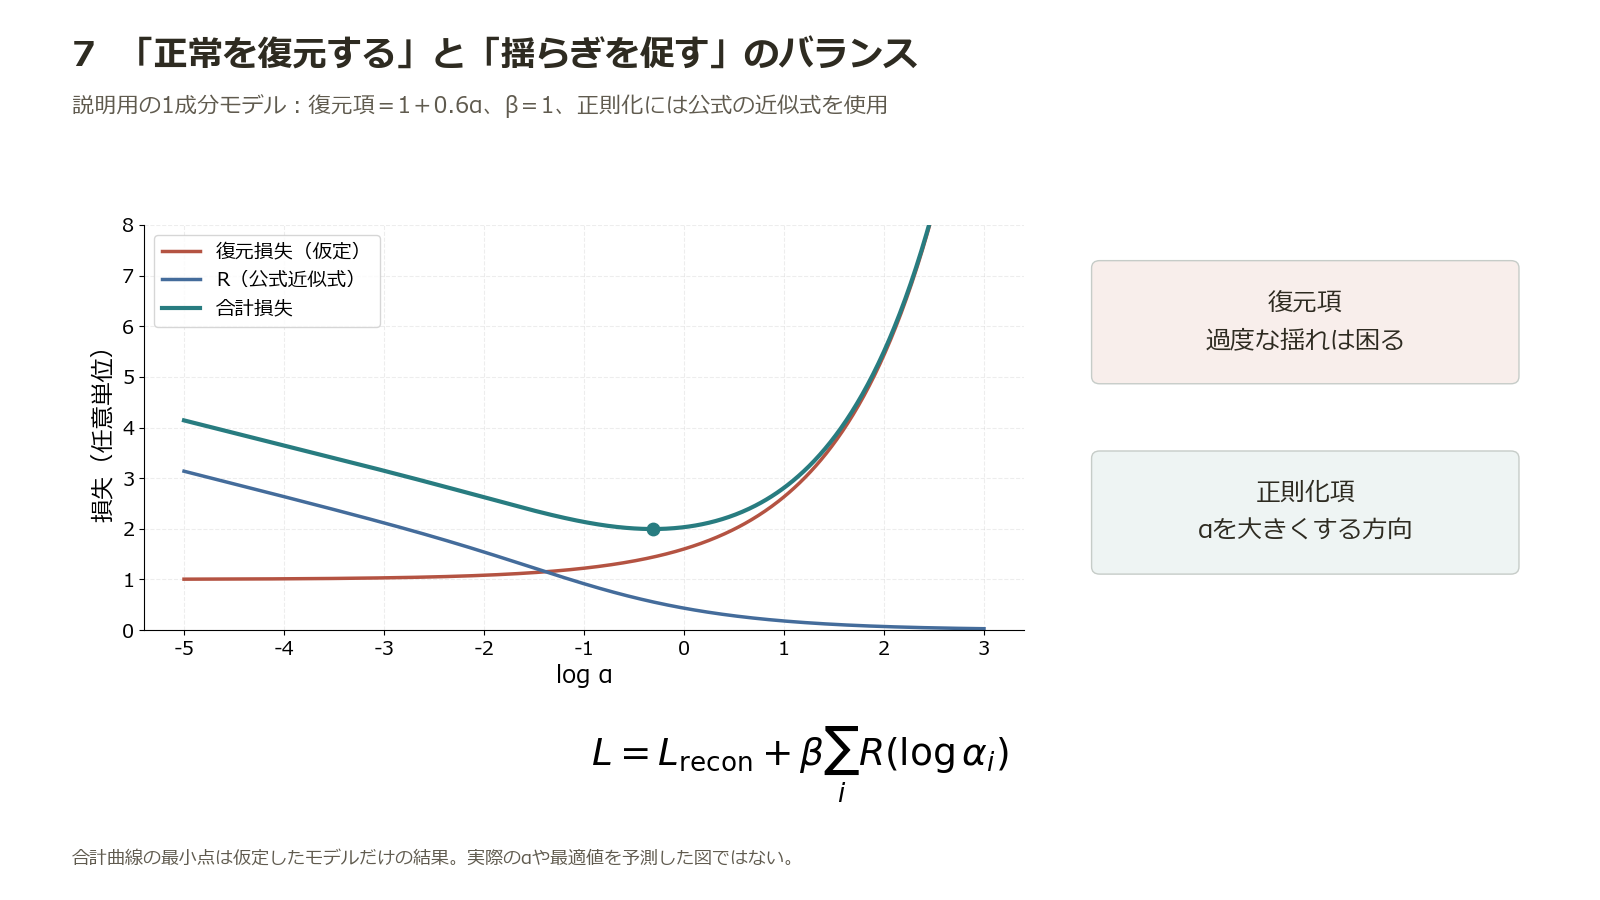

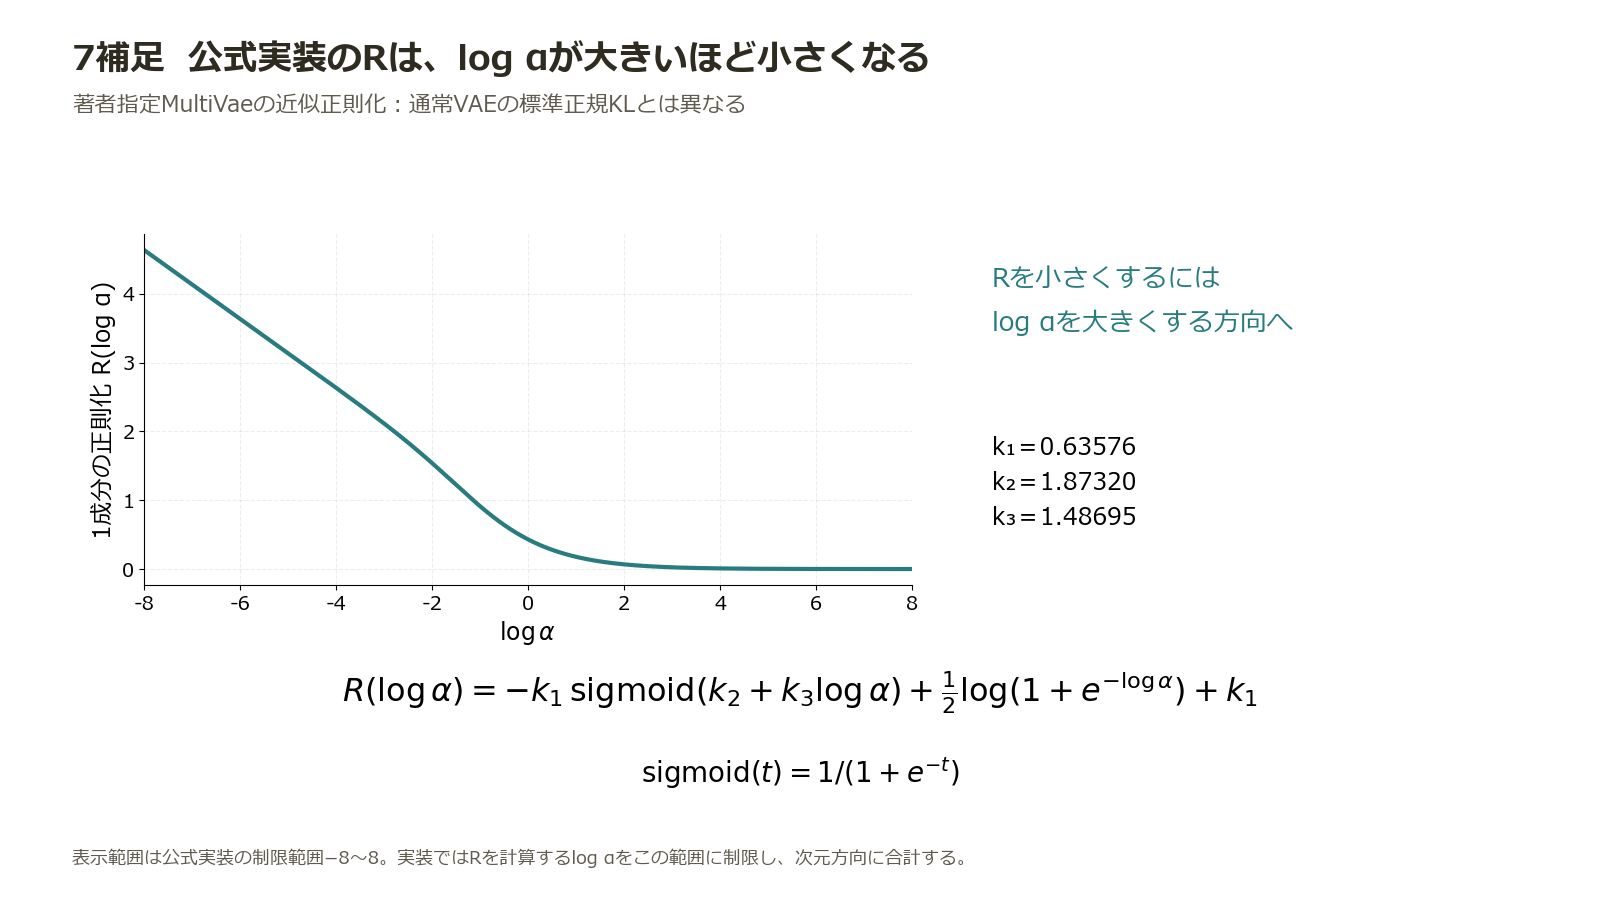

In [8]:
fig=canvas('7  「正常を復元する」と「揺らぎを促す」のバランス','説明用の1成分モデル：復元項＝1＋0.6α、β＝1、正則化には公式の近似式を使用')
ell=np.linspace(-5,3,600);a=np.exp(ell);rec=1+.6*a;reg=sparse_R(ell);total=rec+reg
ax=fig.add_axes([.09,.30,.55,.45]);
ax.plot(ell,rec,color=C['red'],lw=2.5,label='復元損失（仮定）');ax.plot(ell,reg,color=C['blue'],lw=2.5,label='R（公式近似式）');ax.plot(ell,total,color=C['teal'],lw=3,label='合計損失')
i=total.argmin();ax.scatter(ell[i],total[i],s=80,color=C['teal'],zorder=5)
ax.set(xlabel='log α',ylabel='損失（任意単位）',ylim=(0,8));ax.legend(loc='upper left');grid(ax)
ax2=fig.add_axes([.68,.30,.28,.45]);ax2.axis('off')
note(ax2,(.02,.62),'復元項\n過度な揺れは困る',.93,.28,color='#f8eeeb',fontsize=18)
note(ax2,(.02,.15),'正則化項\nαを大きくする方向',.93,.28,color=C['pale'],fontsize=18)
fig.text(.5,.15,r'$L=L_{\mathrm{recon}}+\beta\sum_i R(\log\alpha_i)$',ha='center',fontsize=27)
foot(fig,'合計曲線の最小点は仮定したモデルだけの結果。実際のαや最適値を予測した図ではない。')
finish(fig,'07_復元損失と正則化のバランス')

fig=canvas('7補足  公式実装のRは、log αが大きいほど小さくなる','著者指定MultiVaeの近似正則化：通常VAEの標準正規KLとは異なる')
ax=fig.add_axes([.09,.35,.48,.39]);ell=np.linspace(-8,8,800);ax.plot(ell,sparse_R(ell),lw=3,color=C['teal'])
ax.set(xlabel=r'$\log\alpha$',ylabel='1成分の正則化 R(log α)',xlim=(-8,8));grid(ax)
ax2=fig.add_axes([.62,.38,.33,.34]);ax2.axis('off')
ax2.text(0,.95,'Rを小さくするには\nlog αを大きくする方向へ',fontsize=19,color=C['teal'],va='top',linespacing=1.8)
ax2.text(0,.40,'k₁＝0.63576\nk₂＝1.87320\nk₃＝1.48695',fontsize=17,va='top',linespacing=1.6)
fig.text(.5,.22,r'$R(\log\alpha)=-k_1\,\mathrm{sigmoid}(k_2+k_3\log\alpha)+\frac{1}{2}\log(1+e^{-\log\alpha})+k_1$',ha='center',fontsize=23)
fig.text(.5,.13,r'$\mathrm{sigmoid}(t)=1/(1+e^{-t})$',ha='center',fontsize=20)
foot(fig,'表示範囲は公式実装の制限範囲−8〜8。実装ではRを計算するlog αをこの範囲に制限し、次元方向に合計する。')
finish(fig,'07b_公式近似正則化R')

## 図8：線形デコーダなら、ノイズの負担を式で示せる

$z=\mu(1+\sqrt{\alpha}\epsilon),\ \hat{x}=wz,\ \epsilon\sim N(0,1)$。

$E[(x-\hat{x})^2]=(x-w\mu)^2+w^2\mu^2\alpha$。

εの平均が0なので交差項は消え、分散が1なので二乗の期待値は1です。グラフは**第2項（ノイズ由来の誤差）だけ**を表示します。wを減らすと第1項が増える場合があるため、全損失も必ず減るとは言えません。CNNそのものの式ではありません。

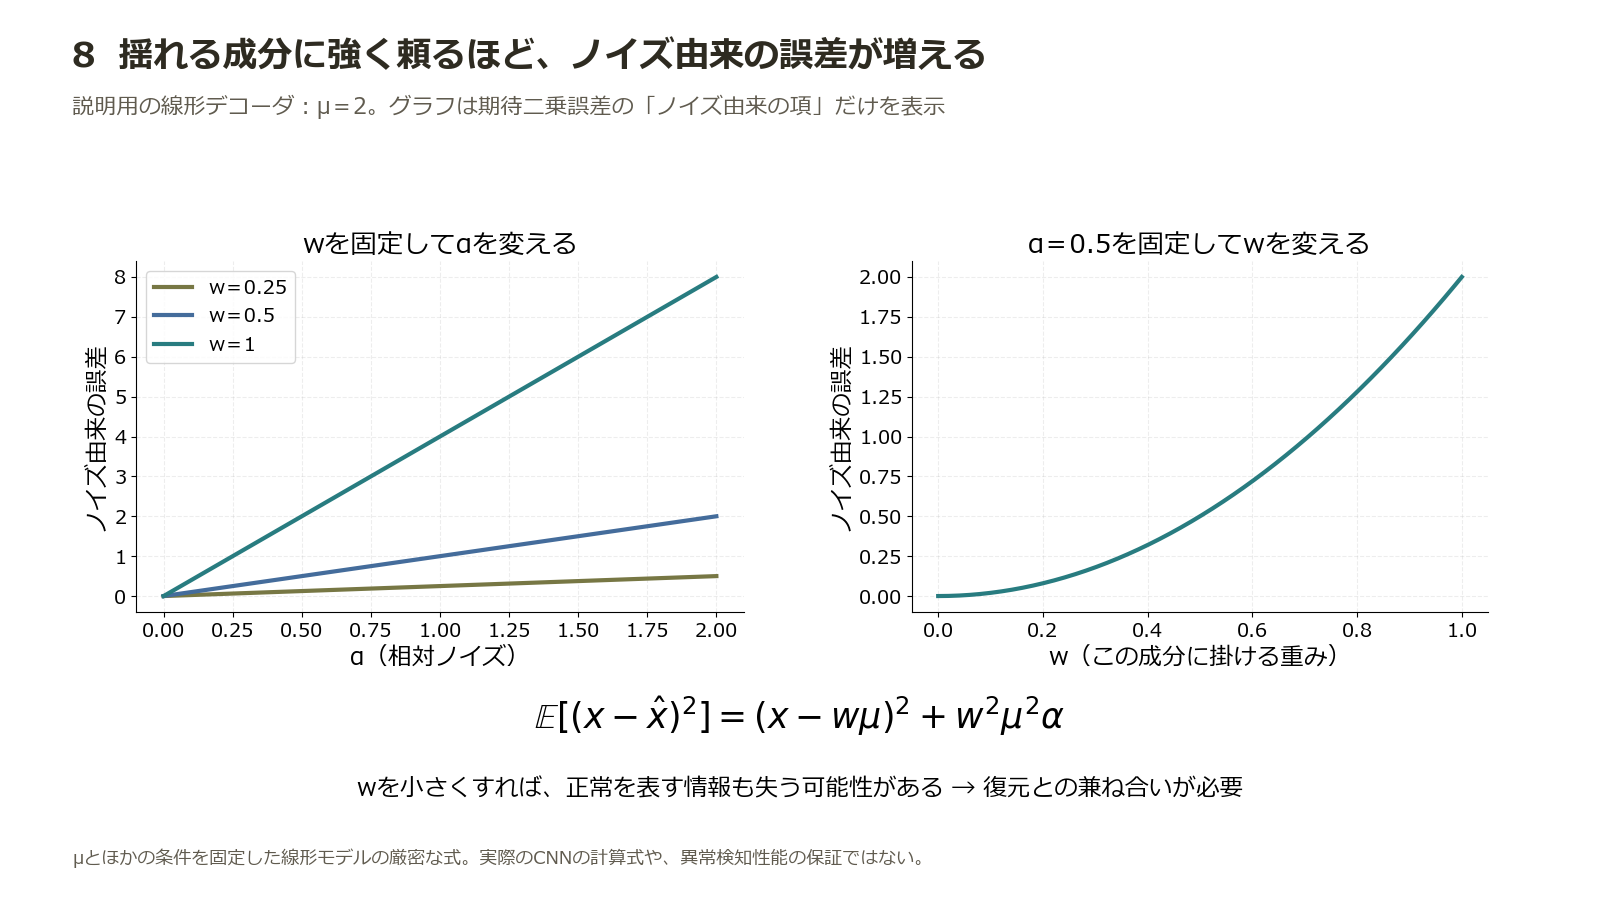

In [9]:
fig=canvas('8  揺れる成分に強く頼るほど、ノイズ由来の誤差が増える','説明用の線形デコーダ：μ＝2。グラフは期待二乗誤差の「ノイズ由来の項」だけを表示')
ax=fig.add_axes([.085,.32,.38,.39]);a=np.linspace(0,2,150)
for w,col in zip([.25,.5,1],[C['olive'],C['blue'],C['teal']]):ax.plot(a,w*w*4*a,lw=3,color=col,label=f'w＝{w:g}')
ax.set(xlabel='α（相対ノイズ）',ylabel='ノイズ由来の誤差',title='wを固定してαを変える');ax.legend();grid(ax)
ax=fig.add_axes([.57,.32,.36,.39]);w=np.linspace(0,1,150);ax.plot(w,w*w*4*.5,lw=3,color=C['teal'])
ax.set(xlabel='w（この成分に掛ける重み）',ylabel='ノイズ由来の誤差',title='α＝0.5を固定してwを変える');grid(ax)
fig.text(.5,.19,r'$\mathbb{E}[(x-\hat{x})^2]=(x-w\mu)^2+w^2\mu^2\alpha$',ha='center',fontsize=25)
fig.text(.5,.115,'wを小さくすれば、正常を表す情報も失う可能性がある → 復元との兼ね合いが必要',ha='center',fontsize=17)
foot(fig,'μとほかの条件を固定した線形モデルの厳密な式。実際のCNNの計算式や、異常検知性能の保証ではない。')
finish(fig,'08_線形デコーダのノイズ誤差')

## 図9：異常検知への応用は、期待する動作として示す

学習時だけ潜在変数をサンプリングし、評価時は中心値μをデコーダに入力する経路を示します。異常入力を必ず正常に戻せるわけではありません。

下段のSSIMは模式画像から実際に計算します。異常度マップ＝1−SSIM、局所窓11×11、data_range=1、上位130**点**の平均。GT欠陥マスクでも、独立した130パッチでもありません。

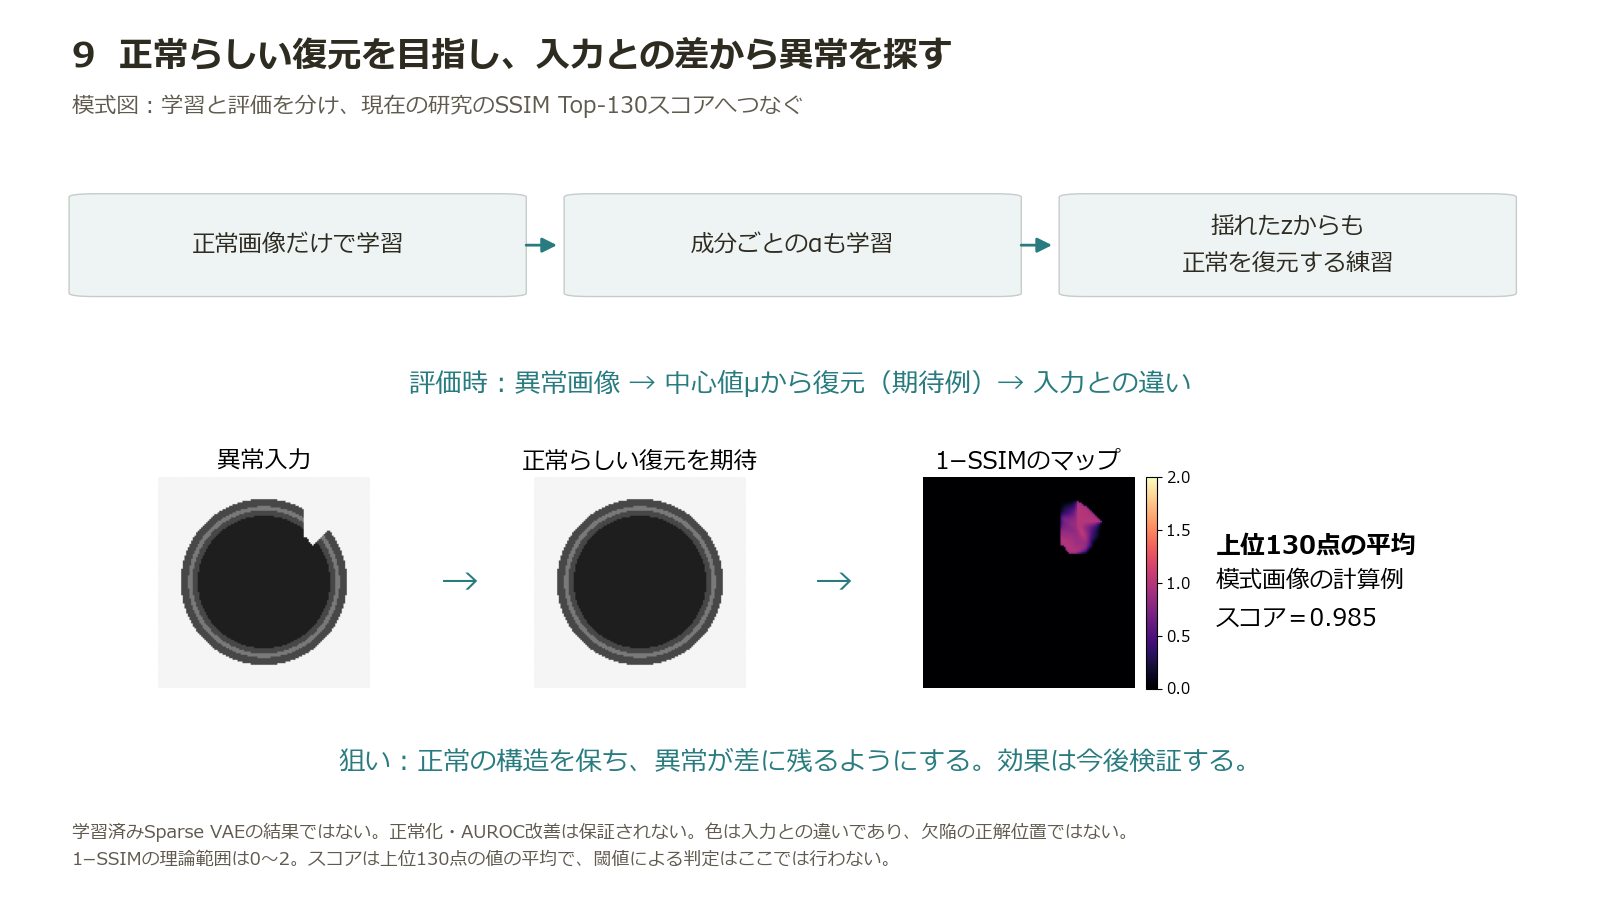

In [10]:
fig=canvas('9  正常らしい復元を目指し、入力との差から異常を探す','模式図：学習と評価を分け、現在の研究のSSIM Top-130スコアへつなぐ')
ax=fig.add_axes([.045,.61,.91,.21]);ax.axis('off')
for x,text in [(.01,'正常画像だけで学習'),(.35,'成分ごとのαも学習'),(.69,'揺れたzからも\n正常を復元する練習')]:note(ax,(x,.30),text,.29,.52,fontsize=17)
arrow(ax,(.31,.56),(.335,.56));arrow(ax,(.65,.56),(.675,.56))
fig.text(.5,.565,'評価時：異常画像 → 中心値μから復元（期待例）→ 入力との違い',ha='center',fontsize=19,color=C['teal'])
_,ssim_map=structural_similarity(ABNORMAL,NORMAL,data_range=1,win_size=11,full=True)
error_map=1-ssim_map
score=float(np.partition(error_map.ravel(),-130)[-130:].mean())
for x,im,title,is_map in [(.075,ABNORMAL,'異常入力',False),(.31,NORMAL,'正常らしい復元を期待',False),(.545,error_map,'1−SSIMのマップ',True)]:
    sub=fig.add_axes([x,.235,.18,.235]);sub.imshow(im,cmap='magma' if is_map else 'gray',vmin=0,vmax=2 if is_map else 1);sub.set_title(title,fontsize=17);sub.axis('off')
    if is_map:
        cb=fig.colorbar(sub.images[0],ax=sub,fraction=.048,pad=.04);cb.ax.tick_params(labelsize=11)
fig.text(.276,.34,'→',fontsize=26,color=C['teal']);fig.text(.51,.34,'→',fontsize=26,color=C['teal'])
fig.text(.76,.385,'上位130点の平均',fontsize=18,weight='bold')
fig.text(.76,.305,f'模式画像の計算例\nスコア＝{score:.3f}',fontsize=17,linespacing=1.7)
fig.text(.5,.145,'狙い：正常の構造を保ち、異常が差に残るようにする。効果は今後検証する。',ha='center',fontsize=19,color=C['teal'])
foot(fig,'学習済みSparse VAEの結果ではない。正常化・AUROC改善は保証されない。色は入力との違いであり、欠陥の正解位置ではない。\n1−SSIMの理論範囲は0〜2。スコアは上位130点の値の平均で、閾値による判定はここでは行わない。')
finish(fig,'09_異常検知とSSIMスコア')

## 数式・出力の検証

平均・分散、線形モデルの期待二乗誤差、公式近似Rの数値と単調性、SSIM Top-130、PNGのサイズ・SVGのXML・文字のキャンバス外へのはみ出しを確認します。これとは別に、保存した全画像を開いて目視確認します。

In [11]:
import xml.etree.ElementTree as ET
# 1. 多数サンプルの平均・分散が理論値に近いこと（固定seed）
eps=np.random.default_rng(SEED).normal(size=500_000)
for mu in [2.,-2.]:
    for alpha in [.05,.5,2.]:
        z=mu*(1+np.sqrt(alpha)*eps)
        assert abs(z.mean()-mu)<.012
        assert np.isclose(z.var(),alpha*mu**2,rtol=.008)
# 2. 平均0・分散1を厳密に満たす±1で、二次式の期待値を照合
for x in [.3,3.]:
    for mu in [-2.,2.]:
        for w in [.1,1.]:
            for alpha in [.05,.5,2.]:
                z=mu*(1+np.sqrt(alpha)*np.array([-1.,1.]))
                expected=(x-w*mu)**2+w*w*mu*mu*alpha
                assert np.isclose(np.mean((x-w*z)**2),expected)
                z_mc=mu*(1+np.sqrt(alpha)*eps)
                assert np.isclose(np.mean((x-w*z_mc)**2),expected,rtol=.012,atol=.012)
# 3. 公式近似式の符号・値・単調性。微分の式は図中には掲載しない。
ell=np.linspace(-8,8,1000)
assert np.all(np.diff(sparse_R(ell))<0)
assert np.isclose(sparse_R(0),.431238951410053,rtol=1e-9)
assert np.isclose(sparse_R(-20,clamp=True),sparse_R(-8))
assert np.isclose(sparse_R(20,clamp=True),sparse_R(8))
s=expit(1.8732+1.48695*ell)
derivative=-.63576*1.48695*s*(1-s)-.5*expit(-ell)
h=1e-5
assert np.allclose((sparse_R(ell+h)-sparse_R(ell-h))/(2*h),derivative,atol=1e-8)
# 4. Top-130と、図1の差の整合性
assert np.isclose(score,np.sort(error_map.ravel())[-130:].mean())
assert np.abs(ABNORMAL-NORMAL).max()>0
assert np.abs(ABNORMAL-ABNORMAL).max()==0
# 5. ファイルの実在・寸法・構造・文字はみ出し
assert len(FIGURES)==11 and len(set(FIGURES))==11
for stem in FIGURES:
    with Image.open(OUT/(stem+'.png')) as im:
        assert im.size==(3200,1800)
        assert im.convert('RGB').getpixel((0,0))==(255,255,255)
    ET.parse(OUT/(stem+'.svg'))
assert not TEXT_WARNINGS, TEXT_WARNINGS
print('数式・数値・全11組のPNG/SVG検証：合格')
print('保存先:',OUT)
print('使用フォント:',FONT)
print('Python:',platform.python_version(),' / NumPy:',np.__version__,' / Matplotlib:',matplotlib.__version__)
print('SSIM模式画像スコア:',round(score,6))

数式・数値・全11組のPNG/SVG検証：合格
保存先: C:\Users\tokiy\my_GitHub\image-anomaly-detection\reports\sparse_vae_theory\figures
使用フォント: Meiryo
Python: 3.13.14  / NumPy: 2.4.6  / Matplotlib: 3.10.9
SSIM模式画像スコア: 0.98535
